# EA2 - Modelo de clasificación y resultado conjunto

**Dataset:** [`mayacheruty/Horse-Race-Prediction-EDA`](https://huggingface.co/datasets/mayacheruty/Horse-Race-Prediction-EDA) (Hugging Face)

Este notebook es **independiente** del de regresión: construye su propio DataFrame, su propio preprocesamiento y su propio modelo. Lo único que toma del otro notebook es el archivo `resultados/regresion.json`, para presentar al final el resultado de ambos modelos juntos.

| Sección | Contenido |
|---|---|
| 1 | Construcción automática del DataFrame |
| 2 | Preprocesamiento para clasificación (antes y después) |
| 3 | Modelo de clasificación e interpretación |
| 4 | Resultado conjunto: regresión lineal + clasificación |

**Requisito:** ejecutar antes `EA2_HorseRace.ipynb`, que guarda `resultados/regresion.json`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import (
    AlmacenResultados,
    ClasificadorBinario,
    HFDatasetLoader,
    InterpretacionModelos,
    PreprocesamientoCarreras,
    ReporteModelos
)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
almacen = AlmacenResultados("resultados")

## 1. Construcción automática del DataFrame

Los datos se descargan de Hugging Face en el momento de la ejecución; no se carga ningún archivo a mano. Detalle del dataset: configuración `default`, split `train` (único), archivo `data/horse_racing_cleaned.csv`, licencia MIT, una fila por caballo en una carrera.

**Problema de clasificación:** predecir `res_win` (1 si el caballo ganó la carrera, 0 si no). La columna ya es binaria en el dataset; no se construye a partir de ninguna variable numérica.

In [2]:
hfdataset = HFDatasetLoader(
    dataset_name="mayacheruty/Horse-Race-Prediction-EDA",
    split="train",
)
df = hfdataset.load()
print(hfdataset.info())
print(f"Filas: {len(df)} | Columnas: {len(df.columns)}")

{'dataset': 'mayacheruty/Horse-Race-Prediction-EDA', 'config': None, 'split': 'train', 'filas': 171849, 'columnas': 24}
Filas: 171849 | Columnas: 24


In [3]:
df.head(10)

,rid,horseName,age,saddle,decimalPrice,isFav,trainerName,jockeyName,position,positionL,dist,weightSt,weightLb,RPR,TR,OR,father,mother,gfather,runners,margin,weight,res_win,res_place
0,11499,Picken,4.0,6.0,0.312500,0,J Size,Joao Moreira,1,None,None,8,13,69.0,NaN,54.0,Duporth,Baby Boom,Redoute's Choice,13,1.217349,56,1.0,1
1,11499,Noble De Love,6.0,7.0,0.333333,1,F C Lor,Zac Purton,2,nk,None,8,12,67.0,NaN,53.0,Commands,Terrenora,Encosta De Lago,13,1.217349,56,0.0,1
2,11499,Fresh Power,5.0,3.0,0.200000,0,Y S Tsui,Silvestre De Sousa,3,2.5,2.75,9,1,63.0,NaN,56.0,Makfi,Bannisters,Redoute's Choice,13,1.217349,57,0.0,1
3,11499,Happy Hour,4.0,5.0,0.017544,0,C H Yip,Umberto Rispoli,4,1.25,4.0,8,13,58.0,NaN,54.0,Mastercraftsman,Jolly Genie,Generous,13,1.217349,56,0.0,0
4,11499,Super Fun,5.0,8.0,0.090909,0,L Ho,Matthew Poon,5,1,5.0,8,9,54.0,NaN,53.0,Dandy Man,Dame Hester,Diktat,13,1.217349,54,0.0,0
5,11499,Blizzing Away,3.0,11.0,0.004587,0,P F Yiu,K C Leung,6,.5,5.5,8,8,49.0,NaN,49.0,All Too Hard,Quackquack,Starcraft,13,1.217349,54,0.0,0
6,11499,Multigogo,5.0,1.0,0.029412,0,A S Cruz,Alberto Sanna,7,nk,5.75,9,5,59.0,NaN,60.0,Drumbeats,Lights Off,Way Of Light,13,1.217349,59,0.0,0
7,11499,Virtus Star,3.0,12.0,0.027027,0,D J Hall,Chad Schofield,8,shd,6.0,8,7,47.0,NaN,48.0,Sebring,Princess Natural,Danehill Dancer,13,1.217349,53,0.0,0
8,11499,Monica,5.0,4.0,0.161290,0,John Moore,Douglas Whyte,9,1,7.0,9,0,51.0,NaN,55.0,Murtajill,Senorita De Lago,Encosta De Lago,13,1.217349,57,0.0,0
9,11499,Regency Gem,4.0,9.0,0.027778,0,W Y So,Alexis Badel,10,.75,7.75,8,11,46.0,NaN,52.0,Showcasing,The Myth,Cape Cross,13,1.217349,55,0.0,0


## 2. Preprocesamiento para clasificación

### 2.1 Estado inicial y variable objetivo

In [4]:
prep = PreprocesamientoCarreras(columna_grupo="rid", test_size=0.2, random_state=42)

print("Filas duplicadas:", int(df.duplicated().sum()))
display(prep.diagnosticar(df))

Filas duplicadas: 0


,tipo,nulos,pct_nulos,distintos
rid,int64,0,0.00,17233
horseName,object,0,0.00,41241
age,float64,0,0.00,15
saddle,float64,0,0.00,41
decimalPrice,float64,0,0.00,586
isFav,int64,0,0.00,2
trainerName,object,0,0.00,3991
jockeyName,object,0,0.00,2929
position,int64,0,0.00,31
positionL,object,25219,14.68,192


,clase,filas,porcentaje
valor,,,
0,No ganó,154589,89.96
1,Ganó,17260,10.04


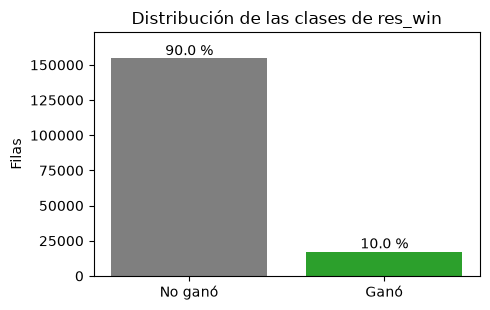

In [5]:
nombres_clases = {0: "No ganó", 1: "Ganó"}
distribucion = PreprocesamientoCarreras.distribucion_clases(df["res_win"].astype(int), nombres_clases)
display(distribucion)

ejes = plt.subplots(figsize=(5, 3.2))[1]
ejes.bar(distribucion["clase"], distribucion["filas"], color=["tab:gray", "tab:green"])
for posicion, (filas, pct) in enumerate(zip(distribucion["filas"], distribucion["porcentaje"])):
    ejes.text(posicion, filas, f"{pct:.1f} %", ha="center", va="bottom")
ejes.set_ylabel("Filas")
ejes.set_ylim(0, distribucion["filas"].max() * 1.12)
ejes.set_title("Distribución de las clases de res_win")
plt.tight_layout()
plt.show()

**Las clases están muy desbalanceadas** (aprox. 90 % / 10 %). Esto condiciona todo el trabajo: un modelo que respondiera siempre "No ganó" acertaría cerca del 90 % sin servir para nada. Por eso se usará un peso de clases balanceado y las métricas se leerán con precisión, recall, F1, PR-AUC y la matriz de confusión, no con la exactitud sola.

### 2.2 Variables elegidas y variables excluidas

| Variable | Decisión | Motivo |
|---|---|---|
| `decimalPrice`, `age`, `weight`, `runners` | **Predictoras** | Se conocen antes de la carrera |
| `OR` | Excluida | 40,65 % de sus valores son la media imputada por el autor del dataset |
| `RPR`, `TR` | Excluidas | Ratings calculados después de la carrera: revelan el resultado |
| `position`, `positionL`, `dist`, `margin`, `res_place` | Excluidas | Describen el resultado de la carrera |
| `weightSt`, `weightLb`, `isFav`, `saddle` | Excluidas | Redundantes con `weight` / `decimalPrice` o sin aporte |
| `horseName`, `trainerName`, `jockeyName`, `father`, `mother`, `gfather` | Excluidas | Texto con miles de valores distintos |
| `rid` | Agrupación | Identifica la carrera; sirve para dividir, no como predictora |

In [6]:
X, y, grupos = prep.preparar_clasificacion(
    df,
    objetivo="res_win",
    predictoras=["decimalPrice", "age", "weight", "runners"],
)
display(prep.resumen_operaciones())

[preparar_clasificacion] X=['decimalPrice', 'age', 'weight', 'runners']; y='res_win'; 171849 filas de 171849; 17233 carreras.


/workspaces/ML_2026_IUD/src/clases_po/preprocesamiento.py:278: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  seleccion[objetivo] = seleccion[objetivo].astype(int)


,operacion,problema_que_resuelve,filas_antes,filas_despues,detalle
0,eliminar_duplicados,Filas repetidas que contarían dos veces en el ...,171849,171849,duplicados eliminados: 0
1,seleccionar_columnas,"Quitar identificadores, texto de alta cardinal...",171849,171849,6 de 24 columnas conservadas
2,descartar_filas_con_nulos,Los modelos no admiten nulos y el objetivo no ...,171849,171849,nulos por columna: ninguno
3,convertir_objetivo,El objetivo llega como número decimal (0.0 / 1...,171849,171849,"'res_win' convertido a entero (clases [0, 1])"


### 2.3 Comparación antes y después

In [7]:
def resumen(frame, nombre, objetivo="res_win"):
    columnas = ["decimalPrice", "age", "weight", "runners"]
    datos = {
        "filas": len(frame),
        "columnas": frame.shape[1],
        "carreras": frame["rid"].nunique(),
        "nulos en las columnas del modelo": int(frame[columnas + [objetivo]].isna().sum().sum()),
        "% de ganadores": round(float(frame[objetivo].mean() * 100), 2),
    }
    for columna in columnas:
        datos[f"{columna} media"] = round(float(frame[columna].mean()), 3)
    return pd.Series(datos, name=nombre)

limpio = pd.concat([X, y, grupos], axis=1)
display(pd.concat([resumen(df, "antes (original)"), resumen(limpio, "después (preparado)")], axis=1))

,antes (original),después (preparado)
filas,171849.000,171849.000
columnas,24.000,6.000
carreras,17233.000,17233.000
nulos en las columnas del modelo,0.000,0.000
% de ganadores,10.040,10.040
decimalPrice media,0.120,0.120
age media,4.826,4.826
weight media,60.644,60.644
runners media,11.388,11.388


### 2.4 División entrenamiento / prueba y escalado

Se divide por carrera (80/20): todos los caballos de una carrera quedan en el mismo conjunto, porque comparten condiciones y algunas variables (`runners`, `decimalPrice` relativo) y mezclarlos haría la evaluación optimista. El escalador se ajusta **solo con el entrenamiento**.

In [8]:
X_train, X_test, y_train, y_test = prep.dividir_por_carrera(X, y, grupos)
grupos_train, grupos_test = grupos.loc[X_train.index], grupos.loc[X_test.index]
display(pd.Series(prep.info_division, name="división").to_frame())

comparacion_clases = pd.concat(
    {
        "entrenamiento": PreprocesamientoCarreras.distribucion_clases(y_train)["porcentaje"],
        "prueba": PreprocesamientoCarreras.distribucion_clases(y_test)["porcentaje"],
    },
    axis=1,
).rename_axis("res_win")
display(comparacion_clases)

[dividir_por_carrera] entrenamiento=137325 filas; prueba=34524 filas; carreras compartidas=0.


,división
filas_entrenamiento,137325.0
filas_prueba,34524.0
carreras_entrenamiento,13786.0
carreras_prueba,3447.0
carreras_compartidas,0.0
test_size,0.2
random_state,42.0


,entrenamiento,prueba
res_win,,
0,89.95,90.0
1,10.05,10.0


In [9]:
X_train_esc, X_test_esc = prep.escalar(X_train, X_test)
display(
    pd.concat(
        {
            "entrenamiento sin escalar (media)": X_train.mean(),
            "entrenamiento escalado (media)": X_train_esc.mean(),
            "entrenamiento escalado (desv.)": X_train_esc.std(),
            "prueba escalada (media)": X_test_esc.mean(),
            "prueba escalada (desv.)": X_test_esc.std(),
        },
        axis=1,
    ).round(3)
)

[escalar] StandardScaler ajustado con entrenamiento y aplicado a prueba.


,entrenamiento sin escalar (media),entrenamiento escalado (media),entrenamiento escalado (desv.),prueba escalada (media),prueba escalada (desv.)
decimalPrice,0.120,0.0,1.0,-0.005,0.993
age,4.827,0.0,1.0,-0.001,0.997
weight,60.649,0.0,1.0,-0.004,0.996
runners,11.379,-0.0,1.0,0.010,1.011


### Conclusiones del preprocesamiento

- Al no usar `OR` ni `RPR`, no hace falta descartar filas con ratings imputados: se conserva casi todo el dataset.
- La proporción de ganadores es prácticamente igual en entrenamiento y prueba, así que la comparación es justa.
- Ninguna carrera aparece en ambos conjuntos y el escalador no vio la prueba.

## 3. Modelo de clasificación e interpretación

### 3.1 Qué se predice, con qué variables y por qué este algoritmo

- **Qué se predice:** si un caballo gana (`res_win = 1`) o no (`0`).
- **Clases:** `0` = No ganó (~90 %), `1` = Ganó (~10 %).
- **Variables:** `decimalPrice` (probabilidad implícita del mercado), `age`, `weight`, `runners`.
- **Algoritmo:** regresión logística (`LogisticRegression` de scikit-learn) con `class_weight="balanced"`.

**Por qué regresión logística:** el objetivo es una categoría binaria; entrega una probabilidad y no solo una etiqueta; sus coeficientes se leen como odds ratios, lo que permite explicar qué favorece ganar; y, como muestra la validación cruzada siguiente, algoritmos más complejos no mejoran el resultado con estas variables.

La comparación usa **únicamente el conjunto de entrenamiento**, con validación cruzada por carrera (`GroupKFold`, 5 particiones); la prueba no interviene en la elección.

In [10]:
clasificador = ClasificadorBinario(umbral=0.5, class_weight="balanced", random_state=prep.random_state)
comparacion_algoritmos = clasificador.comparar_algoritmos(X_train_esc, y_train, grupos_train, n_splits=5)
display(comparacion_algoritmos.round(3))

,precision,recall,f1,roc_auc,pr_auc
Siempre la clase mayoritaria (referencia),0.000,0.000,0.000,0.500,0.101
Regresión logística,0.251,0.627,0.358,0.794,0.338
Gradient boosting (HistGradientBoosting),0.213,0.750,0.332,0.795,0.333
Bosque aleatorio,0.221,0.707,0.337,0.792,0.332


Las tres opciones reales rinden de forma muy parecida (ROC-AUC cercano a 0,79 en todas); la referencia (siempre "No ganó") tiene precisión y recall en cero, pues nunca detecta un ganador. Se elige la regresión logística por ser la más simple e interpretable.

### 3.2 Configuración de entrenamiento y prueba

| Ítem | Valor |
|---|---|
| Algoritmo | `LogisticRegression` (scikit-learn) |
| Manejo del desbalance | `class_weight="balanced"` |
| Umbral de decisión | 0,5 (no se ajusta con la prueba) |
| División | 80 % / 20 % por carrera (`GroupShuffleSplit`), `random_state=42` |
| Preprocesamiento | `StandardScaler` ajustado solo con entrenamiento |
| Persistencia | Modelo y preprocesador guardados en `entrenamiento/` con fecha y hora |

In [11]:
datos_entrenamiento = clasificador.entrenar(X_train_esc, y_train, directorio_entrenamiento="entrenamiento")
modelo = datos_entrenamiento["modelo"]
ruta_modelo = datos_entrenamiento["ruta_modelo"]
ruta_preprocesador = prep.guardar(
    ruta_modelo.with_name(ruta_modelo.name.replace("_clasificador.pkl", "_preprocesador_clasificacion.pkl"))
)
print("Preprocesador guardado en:", ruta_preprocesador)
display(pd.Series(modelo.get_params(), name="valor").astype(str).to_frame())

[entrenar] clasificador ajustado con 137325 filas y 4 características; guardado en: entrenamiento/20261026_091813_390393_clasificador.pkl
Preprocesador guardado en: entrenamiento/20261026_091813_390393_preprocesador_clasificacion.pkl


,valor
C,1.0
class_weight,balanced
dual,False
fit_intercept,True
intercept_scaling,1
l1_ratio,0.0
max_iter,1000
n_jobs,None
penalty,deprecated
random_state,42


### 3.3 Parámetros

Los coeficientes están en escala logarítmica de las odds. El **odds ratio por desviación estándar** es más fácil de leer: mayor que 1 favorece ganar, menor que 1 lo reduce, 1 es sin efecto.

In [12]:
tabla_coef, intercepto_original = clasificador.obtener_parametros(
    ruta_modelo, list(X_train_esc.columns), prep.escalador
)
print(
    f"Intercepto con variables escaladas: {float(modelo.intercept_[0]):.3f} | "
    f"en unidades originales: {intercepto_original:.3f}"
)
display(tabla_coef.round(4))

Intercepto con variables escaladas: -0.353 | en unidades originales: -1.133


,coef_estandarizado,odds_ratio_por_desv,desv_variable,coef_unidad_original,peso_relativo_pct
decimalPrice,1.0251,2.7873,0.1187,8.6345,93.2643
runners,-0.0533,0.9481,3.9415,-0.0135,4.8510
weight,-0.0131,0.9870,6.6082,-0.0020,1.1946
age,0.0076,1.0076,2.1611,0.0035,0.6901


### 3.4 Resultados

In [13]:
grupos_prueba = grupos_test
metricas_test = clasificador.evaluar(ruta_modelo, X_test_esc, y_test, grupos=grupos_prueba)
metricas_train = clasificador.evaluar(ruta_modelo, X_train_esc, y_train, grupos=grupos_train)

claves = ["exactitud", "exactitud_baseline", "exactitud_balanceada", "precision", "recall", "f1", "roc_auc", "pr_auc", "pr_auc_azar"]
display(pd.DataFrame({"entrenamiento": {k: metricas_train[k] for k in claves}, "prueba": {k: metricas_test[k] for k in claves}}).round(3))

,entrenamiento,prueba
exactitud,0.774,0.775
exactitud_baseline,0.899,0.900
exactitud_balanceada,0.709,0.705
precision,0.251,0.249
recall,0.627,0.617
f1,0.358,0.354
roc_auc,0.794,0.792
pr_auc,0.337,0.332
pr_auc_azar,0.101,0.100


**Métricas elegidas, dado el desbalance (~10 % de positivos):**

- **Exactitud:** se muestra solo como referencia; siempre responder "No ganó" ya da ~90 %.
- **Precisión:** de los caballos que el modelo marca como ganadores, cuántos lo son.
- **Recall:** de los ganadores reales, cuántos detecta el modelo.
- **F1:** media armónica de precisión y recall; resume el equilibrio.
- **Exactitud balanceada:** promedio del acierto en cada clase (0,5 = azar).
- **ROC-AUC / PR-AUC:** miden qué tan bien el modelo ordena a los ganadores por encima de los demás, sin depender del umbral. PR-AUC se compara con la tasa de positivos (lo que lograría el azar).

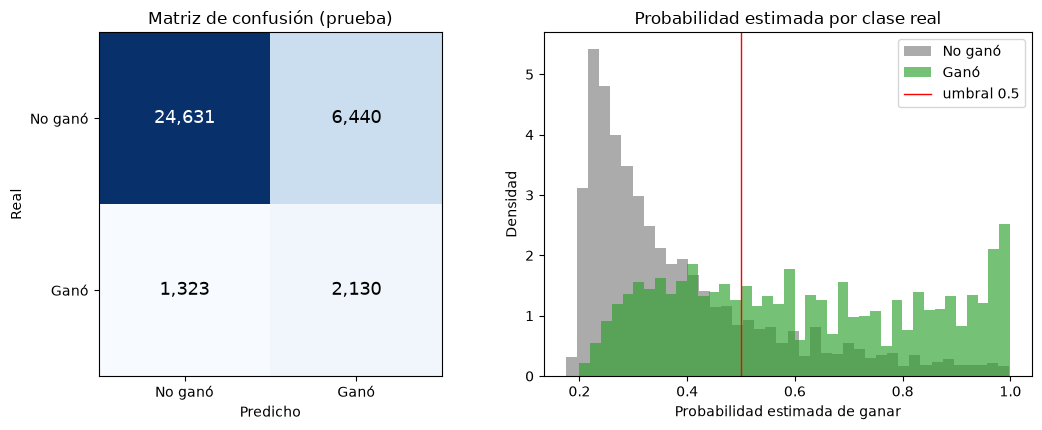

In [14]:
matriz = np.array(metricas_test["matriz_confusion"])
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.4))

ejes[0].imshow(matriz, cmap="Blues")
for i in range(2):
    for j in range(2):
        ejes[0].text(j, i, f"{matriz[i, j]:,}", ha="center", va="center",
                     color="white" if matriz[i, j] > matriz.max() / 2 else "black", fontsize=13)
ejes[0].set_xticks([0, 1], ["No ganó", "Ganó"])
ejes[0].set_yticks([0, 1], ["No ganó", "Ganó"])
ejes[0].set_xlabel("Predicho")
ejes[0].set_ylabel("Real")
ejes[0].set_title("Matriz de confusión (prueba)")

prob_test = clasificador.predecir_probabilidad(ruta_modelo, X_test_esc)
ejes[1].hist(prob_test[y_test.to_numpy() == 0], bins=40, alpha=0.65, label="No ganó", color="tab:gray", density=True)
ejes[1].hist(prob_test[y_test.to_numpy() == 1], bins=40, alpha=0.65, label="Ganó", color="tab:green", density=True)
ejes[1].axvline(clasificador.umbral, color="red", linewidth=1, label=f"umbral {clasificador.umbral}")
ejes[1].set_xlabel("Probabilidad estimada de ganar")
ejes[1].set_ylabel("Densidad")
ejes[1].set_title("Probabilidad estimada por clase real")
ejes[1].legend()
plt.tight_layout()
plt.show()

In [15]:
print("Sensibilidad al umbral (informativa: el umbral del modelo se mantiene en 0,5)")
display(ClasificadorBinario.sensibilidad_umbral(y_test, prob_test).round(3))

Sensibilidad al umbral (informativa: el umbral del modelo se mantiene en 0,5)


,predichos_positivos,precision,recall,f1
umbral,,,,
0.3,20565,0.154,0.915,0.263
0.4,13031,0.202,0.764,0.320
0.5,8570,0.249,0.617,0.354
0.6,5647,0.292,0.478,0.362
0.7,3713,0.343,0.369,0.356


In [16]:
interpretacion = InterpretacionModelos.interpretar_clasificacion(
    objetivo="res_win",
    metricas_train=metricas_train,
    metricas_test=metricas_test,
    coeficientes=tabla_coef,
    comparacion=comparacion_algoritmos,
)
display(Markdown("### 3.5 Interpretación de los resultados\n\n" + "\n".join(f"- {linea}" for linea in interpretacion)))

### 3.5 Interpretación de los resultados

- Desbalance: solo el 10.0 % de las filas de prueba son 'ganó' (res_win = 1). Un modelo que siempre responde 'no' tendría exactitud 90.0 % sin detectar ningún caso, por eso la exactitud (77.5 %) no es la métrica principal: aquí es menor que esa referencia porque el modelo prefiere señalar más positivos para no dejar escapar los reales.
- Matriz de confusión: de 3453 casos positivos reales el modelo acertó 2130 (recall 61.7 %) y dejó pasar 1323; de 8570 casos que marcó como positivos, 2130 lo eran (precisión 24.9 %) y 6440 no.
- F1 = 0.354 (balance entre precisión y recall) y exactitud balanceada 0.705 (promedio del acierto en cada clase; 0,5 equivale a azar).
- Capacidad de ordenar: ROC-AUC 0.792 (0,5 es azar, 1 es perfecto) y PR-AUC 0.332 frente a 0.100 que obtendría el azar; la señal existe pero es moderada.
- Por carrera: el caballo con mayor probabilidad estimada ganó en 33.7 % de las 3447 carreras de prueba; elegir al azar daría 11.6 %.
- Coeficientes: decimalPrice concentra el 93 % del peso relativo. Por cada desviación estándar adicional de decimalPrice, las odds de ganar se multiplican por 2.79 (aumenta la probabilidad), con las demás variables constantes.
- Efecto de las demás variables: runners (x0.95 por desviación estándar); weight (x0.99 por desviación estándar); age (x1.01 por desviación estándar).
- Variables con efecto casi nulo (odds ratio entre 0,95 y 1,05): weight, age. Los signos describen asociación, no causalidad.
- Generalización: F1 de 0.358 en entrenamiento y 0.354 en prueba (diferencia +0.004); no se observa sobreajuste.
- Errores: 6440 falsos positivos (caballos señalados que no ganaron) frente a 1323 falsos negativos (ganadores no detectados). Con el umbral 0.50 y el peso de clases balanceado el modelo acepta más falsos positivos a cambio de un recall mayor; subir el umbral invierte ese intercambio.
- Elección del algoritmo: en validación cruzada por carrera (solo entrenamiento) los algoritmos comparados difieren como máximo 0.026 en F1 (mejor: Regresión logística, 0.358). Al ser una diferencia pequeña, se conserva la regresión logística por ser la más simple e interpretable.

In [17]:
limitaciones = InterpretacionModelos.limitaciones_clasificacion(
    objetivo="res_win",
    filas_originales=len(df),
    filas_usadas=len(X),
    metricas_test=metricas_test,
    predictoras=list(X_train_esc.columns),
)
display(Markdown("### 3.6 Limitaciones\n\n" + "\n".join(f"- {linea}" for linea in limitaciones)))

### 3.6 Limitaciones

- La precisión es baja (24.9 %): la mayoría de los caballos que el modelo señala como ganadores no ganan. Sirve para priorizar, no para decidir.
- Solo hay 4 predictoras previas a la carrera (decimalPrice, age, weight, runners). Ganar depende de factores que el dataset no contiene (estado del caballo, ritmo, terreno), y probar otros algoritmos no mejoró el resultado, señal de que el límite está en la información y no en el modelo.
- Una carrera tiene exactamente un ganador, pero el modelo puntúa a cada caballo por separado y puede marcar varios (o ninguno) como ganadores de la misma carrera.
- Se excluyeron RPR y TR porque se calculan después de la carrera (revelarían el resultado) y OR porque gran parte de sus valores están imputados con la media.
- El peso de clases balanceado mejora el recall a costa de la precisión; el umbral 0,5 no se optimizó. Las probabilidades que entrega no están calibradas.

In [19]:
resultados_clasificacion = {
    "dataset": hfdataset.info(),
    "preprocesamiento": prep.resumen_operaciones().to_dict("records"),
    "objetivo": "res_win",
    "clases": {"0": "No ganó", "1": "Ganó"},
    "distribucion_clases": distribucion.reset_index().to_dict("records"),
    "predictoras": list(X_train_esc.columns),
    "algoritmo": "Regresión logística (LogisticRegression) con class_weight='balanced'",
    "hiperparametros": {k: str(v) for k, v in modelo.get_params().items()},
    "configuracion": {
        **prep.info_division,
        "division": "por carrera (GroupShuffleSplit)",
        "escalado": "StandardScaler ajustado solo con entrenamiento",
        "umbral": clasificador.umbral,
    },
    "ruta_modelo": str(ruta_modelo),
    "intercepto_original": intercepto_original,
    "coeficientes": tabla_coef.round(6).reset_index(names="variable").to_dict("records"),
    "metricas_entrenamiento": metricas_train,
    "metricas_prueba": metricas_test,
    "comparacion_algoritmos": comparacion_algoritmos.round(6).reset_index(names="algoritmo").to_dict("records"),
    "filas_originales": len(df),
    "filas_usadas": len(X),
    "interpretacion": interpretacion,
    "limitaciones": limitaciones,
}
ruta_resultados = almacen.guardar("clasificacion", resultados_clasificacion)
print("Resultados de la clasificación guardados en:", ruta_resultados)

Resultados de la clasificación guardados en: resultados/clasificacion.json


## 4. Resultado conjunto: regresión lineal + clasificación

Se carga el resultado guardado por `EA2_HorseRace.ipynb` y se junta con el obtenido arriba.

In [20]:
resultados_regresion = almacen.cargar("regresion")  # falla con un mensaje claro si falta ejecutar la regresión
resultados_clasificacion = almacen.cargar("clasificacion")  # incluye la fecha de ejecución

print("Regresión ejecutada el:", resultados_regresion["fecha_ejecucion"])
print("Clasificación ejecutada el:", resultados_clasificacion["fecha_ejecucion"])

mr, mc = resultados_regresion["metricas_prueba"], resultados_clasificacion["metricas_prueba"]
resumen_modelos = pd.DataFrame(
    {
        "Regresión lineal": {
            "Objetivo": resultados_regresion["objetivo"] + " (numérico)",
            "Algoritmo": "LinearRegression",
            "Predictoras": ", ".join(resultados_regresion["predictoras"]),
            "Filas usadas": resultados_regresion["filas_usadas"],
            "Métrica principal": f"R² = {mr['r2']:.3f}",
            "Otras métricas": f"MAE = {mr['mae']:.2f} | RMSE = {mr['rmse']:.2f}",
            "Referencia": f"Predecir la media: MAE = {resultados_regresion['metricas_baseline']['mae']:.2f}",
        },
        "Clasificación": {
            "Objetivo": resultados_clasificacion["objetivo"] + " (binario)",
            "Algoritmo": "LogisticRegression (balanced)",
            "Predictoras": ", ".join(resultados_clasificacion["predictoras"]),
            "Filas usadas": resultados_clasificacion["filas_usadas"],
            "Métrica principal": f"F1 = {mc['f1']:.3f}",
            "Otras métricas": f"Precisión = {mc['precision']:.3f} | Recall = {mc['recall']:.3f} | ROC-AUC = {mc['roc_auc']:.3f}",
            "Referencia": f"Siempre 'No ganó': exactitud = {mc['exactitud_baseline']:.3f}, F1 = 0",
        },
    }
)
display(resumen_modelos)

Regresión ejecutada el: 2026-10-26T09:12:48
Clasificación ejecutada el: 2026-10-26T09:19:49


,Regresión lineal,Clasificación
Objetivo,RPR (numérico),res_win (binario)
Algoritmo,LinearRegression,LogisticRegression (balanced)
Predictoras,"OR, age, weight, decimalPrice, runners","decimalPrice, age, weight, runners"
Filas usadas,94740,171849
Métrica principal,R² = 0.740,F1 = 0.354
Otras métricas,MAE = 11.33 | RMSE = 15.11,Precisión = 0.249 | Recall = 0.617 | ROC-AUC =...
Referencia,Predecir la media: MAE = 23.75,"Siempre 'No ganó': exactitud = 0.900, F1 = 0"


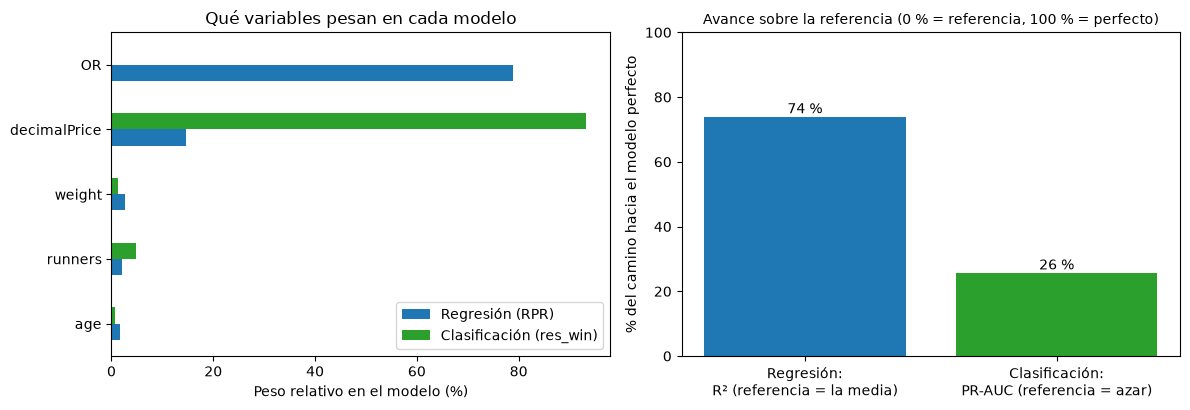

In [21]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))

pesos_reg = pd.DataFrame(resultados_regresion["coeficientes"]).set_index("variable")["peso_relativo_pct"]
pesos_clf = pd.DataFrame(resultados_clasificacion["coeficientes"]).set_index("variable")["peso_relativo_pct"]
pesos = pd.concat({"Regresión (RPR)": pesos_reg, "Clasificación (res_win)": pesos_clf}, axis=1).fillna(0)
pesos.sort_values("Regresión (RPR)").plot.barh(ax=ejes[0], color=["tab:blue", "tab:green"])
ejes[0].set_xlabel("Peso relativo en el modelo (%)")
ejes[0].set_ylabel("")
ejes[0].set_title("Qué variables pesan en cada modelo")

avance_reg = mr["r2"] * 100
avance_clf = (mc["pr_auc"] - mc["pr_auc_azar"]) / (1 - mc["pr_auc_azar"]) * 100
ejes[1].bar(["Regresión:\nR² (referencia = la media)", "Clasificación:\nPR-AUC (referencia = azar)"],
            [avance_reg, avance_clf], color=["tab:blue", "tab:green"])
for posicion, valor in enumerate([avance_reg, avance_clf]):
    ejes[1].text(posicion, valor, f"{valor:.0f} %", ha="center", va="bottom")
ejes[1].set_ylim(0, 100)
ejes[1].set_ylabel("% del camino hacia el modelo perfecto")
ejes[1].set_title("Avance sobre la referencia (0 % = referencia, 100 % = perfecto)", fontsize=10)
plt.tight_layout()
plt.show()

In [22]:
conclusiones = InterpretacionModelos.conclusion_conjunta(resultados_regresion, resultados_clasificacion)
display(Markdown("### Conclusiones conjuntas\n\n" + "\n".join(f"- {linea}" for linea in conclusiones)))

conjunto = {
    "regresion": resultados_regresion,
    "clasificacion": resultados_clasificacion,
    "conclusiones": conclusiones,
}
ruta_conjunto = almacen.guardar("conjunto", conjunto)
print("Resultado conjunto guardado en:", ruta_conjunto)

### Conclusiones conjuntas

- Regresión (RPR): explica el 74.0 % de la variación con un error medio de 11.33 puntos (baseline 23.75). Funciona bien porque OR ya contiene casi toda la información (R² = 0.718 por sí sola).
- Clasificación (res_win): ROC-AUC 0.792, recall 61.7 % y precisión 24.9 %. Hay señal, pero es mucho más débil que en la regresión.
- Contraste: el mismo conjunto de datos permite estimar con buena precisión un rating de desempeño y apenas ordenar quién ganará. Ganar es un evento raro (10.0 %) y depende de factores ausentes en los datos; el rating, en cambio, está fuertemente ligado a otro rating previo.
- Variables comunes: age, decimalPrice, runners, weight. La regresión usa además el rating oficial (OR), que no puede entrar en la clasificación sin perder filas ni arriesgar fuga de información.
- Ambos modelos describen asociaciones en datos históricos; ninguno debe usarse como base única para decisiones de apuesta.

Resultado conjunto guardado en: resultados/conjunto.json


## 5. Resumen automático en `.txt`

El archivo se genera por código a partir de los resultados conjuntos: dataset, preprocesamiento, y para cada modelo su objetivo, variables, algoritmo, parámetros, configuración, métricas, interpretación, fecha de ejecución, conclusiones y limitaciones. No contiene cifras escritas a mano.

In [23]:
ruta_reporte = ReporteModelos("resultados").generar(conjunto)
print("Reporte generado en:", ruta_reporte)
print()
print(ruta_reporte.read_text(encoding="utf-8"))

Reporte generado en: resultados/resumen_modelos_20261026_092229.txt

RESUMEN DE MODELOS - EA2

Reporte generado el:            2026-10-26T09:22:29
Regresión ejecutada el:         2026-10-26T09:12:48
Clasificación ejecutada el:     2026-10-26T09:19:49

--------------------------------------------------------------------------------------------
1. DATASET
--------------------------------------------------------------------------------------------
Dataset:            mayacheruty/Horse-Race-Prediction-EDA
Origen:             Hugging Face (descarga automática al ejecutar)
Split:              train
Filas originales:   171849
Columnas:           24
Contenido:          una fila por caballo en una carrera (edad, peso, cuota de
                    mercado, ratings, resultado).

--------------------------------------------------------------------------------------------
2. PREPROCESAMIENTO
--------------------------------------------------------------------------------------------
Regresión (obje